# Heart Disease MLOps — reviewed notebook

This version removes duplicate training/MLflow cells, avoids imputing missing values before the train/test split, and logs model metrics plus saved EDA plots to MLflow. Run the notebook from top to bottom in a clean kernel so all variables, plots, and experiment runs are generated consistently.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Create project directories
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("reports/figures", exist_ok=True)

# Download dataset from the UCI repository
heart_disease = fetch_ucirepo(id=45)

# Extract features and target
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

# Display first five rows
display(df.head())

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Dataset downloaded successfully!
Dataset shape: (303, 14)


In [3]:
df.to_csv("data/raw/heart_disease.csv", index=False)

print("Raw dataset saved successfully!")

Raw dataset saved successfully!


In [4]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions: (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values per co

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [5]:
# Create a working copy
df_clean = df.copy()

# Display the first five rows
display(df_clean.head())

# Check the number of rows and columns
print("Dataset shape:", df_clean.shape)

# Check column names
print("\nColumns:")
print(df_clean.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df_clean.info()

print("\nMissing values per column:")
print(df_clean.isnull().sum())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Dataset shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values per column:
age         0


In [6]:
print("Target columns:", y.columns.tolist())

for col in y.columns:
    print(f"\nValues in target column '{col}':")
    print(y[col].value_counts(dropna=False).sort_index())

Target columns: ['num']

Values in target column 'num':
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


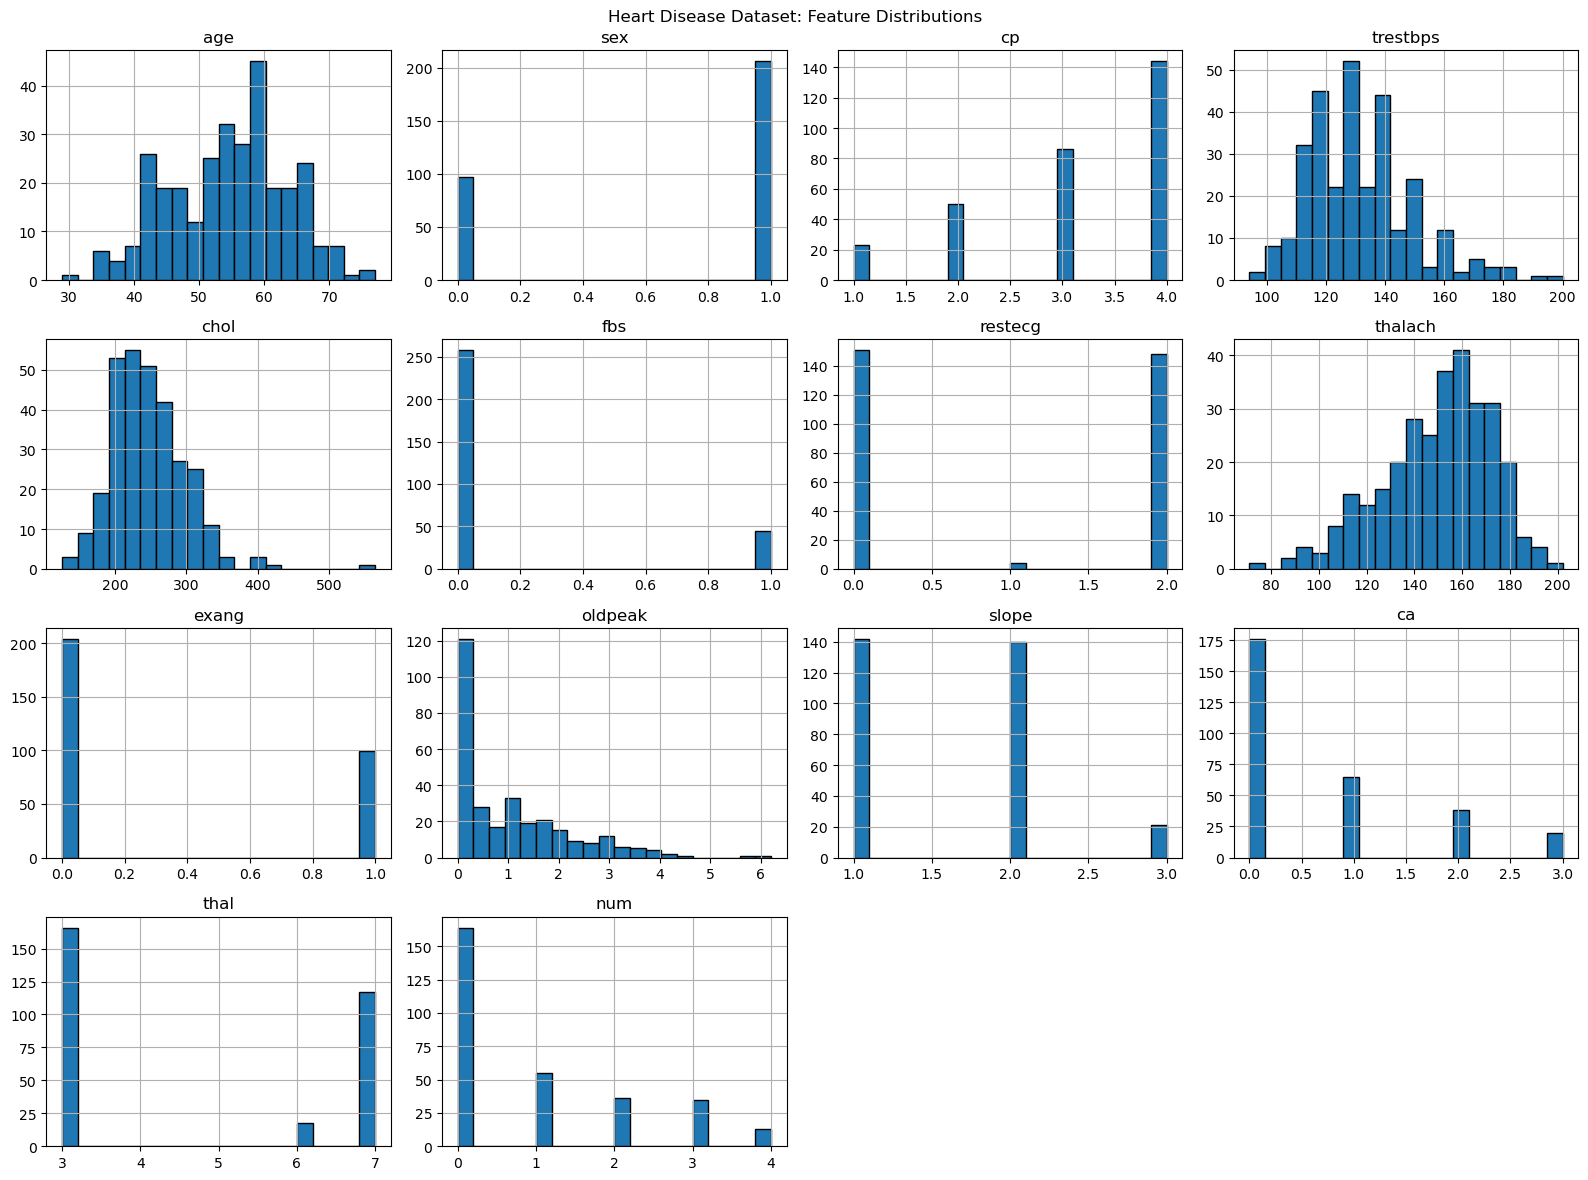

In [7]:
# Select numeric columns
numeric_df = df_clean.select_dtypes(include="number")

# Plot and save histograms
numeric_df.hist(figsize=(16, 12), bins=20, edgecolor="black")
plt.suptitle("Heart Disease Dataset: Feature Distributions")
plt.tight_layout()
plt.savefig(
    "reports/figures/feature_histograms.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


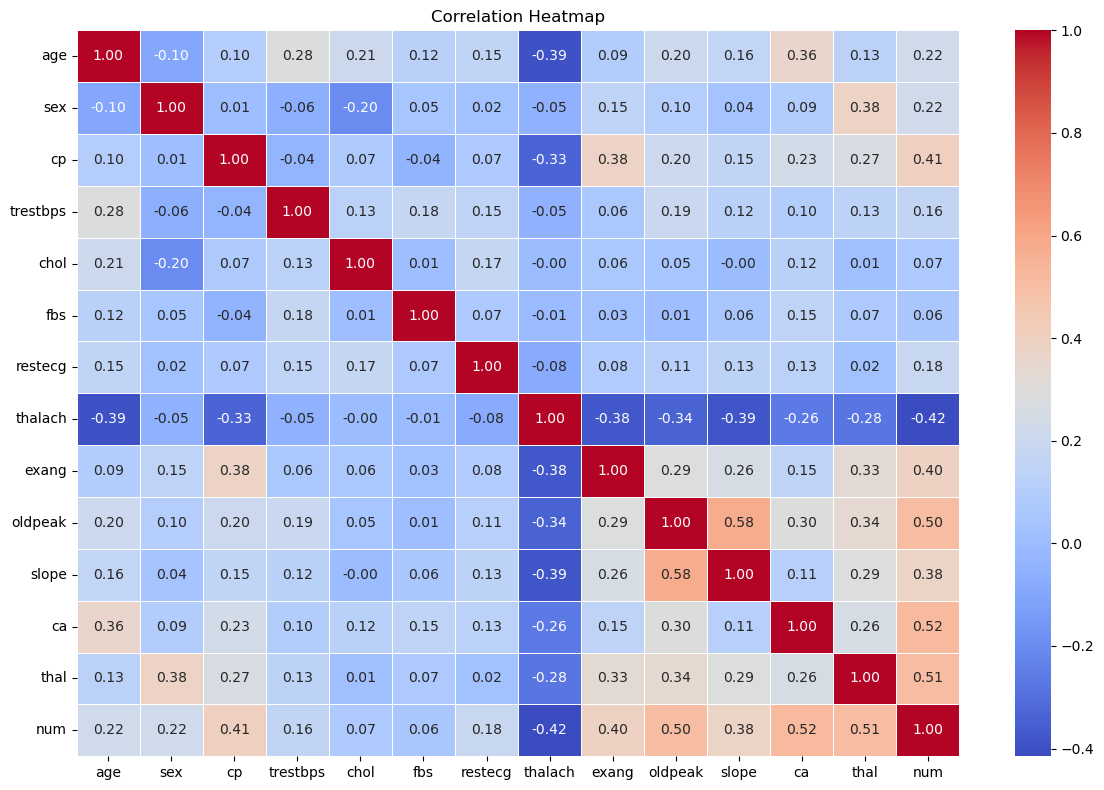

In [8]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    "reports/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [9]:
# Create a binary target:
# 0 = no detected heart disease
# 1 = heart disease present (original num > 0)

df_clean["target"] = (df_clean["num"] > 0).astype(int)

print("Binary target distribution:")
print(df_clean["target"].value_counts().sort_index())

print("\nTarget labels:")
print("0 = No detected heart disease")
print("1 = Heart disease present")

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Target labels:
0 = No detected heart disease
1 = Heart disease present


In [10]:
# Inspect missing values without imputing on the full dataset.
# Missing values are handled inside the sklearn preprocessing Pipeline after the
# train/test split, preventing information from the test set leaking into training.
print("Missing values before model preprocessing:")
print(df_clean[["ca", "thal"]].isnull().sum())

print("\nTotal missing values in the working dataset:", df_clean.isnull().sum().sum())
print(
    "\nNote: missing feature values are intentionally retained here; "
    "SimpleImputer is fitted inside the training pipeline."
)


Missing values before model preprocessing:
ca      4
thal    2
dtype: int64

Total missing values in the working dataset: 6

Note: missing feature values are intentionally retained here; SimpleImputer is fitted inside the training pipeline.


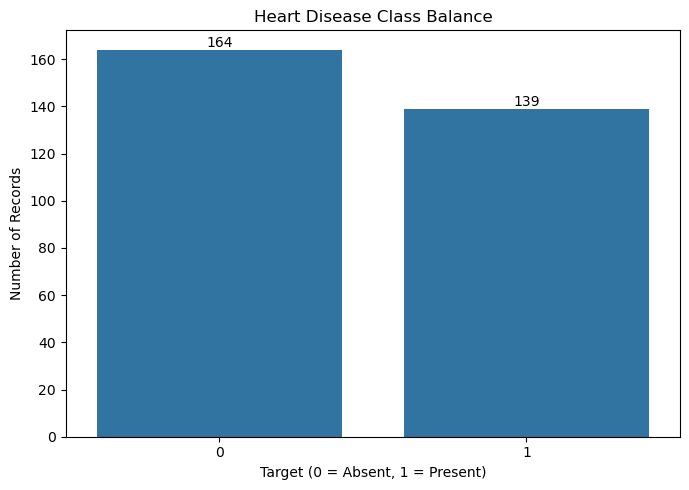

In [11]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_clean, x="target")
ax.set_title("Heart Disease Class Balance")
ax.set_xlabel("Target (0 = Absent, 1 = Present)")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("reports/figures/class_balance.png", dpi=300, bbox_inches="tight")
plt.show()


In [12]:
# Save a separate processed dataset
df_clean.to_csv(
    "data/processed/heart_disease_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaned dataset saved successfully!
Final dataset shape: (303, 15)
Remaining missing values: 6


In [13]:
print("Final dataset shape:", df_clean.shape)

print("\nBinary target counts:")
print(df_clean["target"].value_counts())

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nSaved dataset exists:",
      os.path.exists("data/processed/heart_disease_cleaned.csv"))

print("\nSaved class balance chart exists:",
      os.path.exists("reports/figures/class_balance.png"))

Final dataset shape: (303, 15)

Binary target counts:
target
0    164
1    139
Name: count, dtype: int64

Missing values:
6

Saved dataset exists: True

Saved class balance chart exists: True


In [14]:
from sklearn.model_selection import train_test_split

# Input features: exclude both target columns
X = df_clean.drop(columns=["num", "target"])

# Binary prediction target
y = df_clean["target"]

# Identify numerical and categorical features
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical features: fill missing values and scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values and encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# Model 2: Random Forest
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train both models
logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully!")
print("Random Forest trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

results = []

for name, model in models.items():
    # Predict classes and positive-class probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results)
display(results_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion matrix:
[[28  5]
 [ 2 26]]

Random Forest
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion matrix:
[[28  5]
 [ 2 26]]


,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.885,0.839,0.929,0.966
1,Random Forest,0.885,0.839,0.929,0.945


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV ROC-AUC
0,Logistic Regression,0.847,0.877,0.783,0.902
1,Random Forest,0.793,0.785,0.756,0.894


In [19]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)
print("Best CV ROC-AUC:", round(logistic_grid.best_score_, 3))

Best Logistic Regression parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best CV ROC-AUC: 0.903


In [20]:
rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best CV ROC-AUC:", round(rf_grid.best_score_, 3))

Best Random Forest parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Best CV ROC-AUC: 0.903


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)
import pandas as pd

tuned_models = {
    "Tuned Logistic Regression": logistic_grid.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_df = pd.DataFrame(tuned_results).round(3)
display(tuned_df)

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Tuned Logistic Regression,0.885,0.839,0.929,0.965
1,Tuned Random Forest,0.902,0.844,0.964,0.951


In [22]:
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

best_model = rf_grid.best_estimator_

joblib.dump(
    best_model,
    model_dir / "heart_disease_model.joblib"
)

print("Saved model to:", model_dir / "heart_disease_model.joblib")

Saved model to: models/heart_disease_model.joblib


In [23]:
feature_columns = X_train.columns.tolist()

joblib.dump(
    feature_columns,
    model_dir / "feature_columns.joblib"
)

print("Saved feature columns:", feature_columns)

Saved feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [24]:
import mlflow

print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.1


In [25]:
import mlflow
from pathlib import Path

# Create a folder for model artifacts
Path("mlartifacts").mkdir(parents=True, exist_ok=True)

# Use SQLite instead of the deprecated filesystem tracking backend
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Create or select the experiment
mlflow.set_experiment("Heart_Disease_Classification")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment configured successfully!")

Tracking URI: sqlite:///mlflow.db
Experiment configured successfully!


In [26]:
print("logistic_pipeline exists:", "logistic_pipeline" in globals())
print("random_forest_pipeline exists:", "random_forest_pipeline" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())

logistic_pipeline exists: True
random_forest_pipeline exists: True
X_train exists: True
X_test exists: True


In [27]:
import mlflow
import mlflow.sklearn
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Heart_Disease_Classification")

models_to_track = {
    "Tuned_Logistic_Regression": logistic_grid,
    "Tuned_Random_Forest": rf_grid,
}

# Log each tuned model once, including its CV/test metrics, model artifact,
# and EDA figures. The GridSearchCV object is used to access best_params_
# and best_score_; its best_estimator_ is the model that is evaluated/logged.
for run_name, grid in models_to_track.items():
    model = grid.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    with mlflow.start_run(run_name=run_name):
        mlflow.log_param("model_name", run_name)
        mlflow.log_params(grid.best_params_)

        mlflow.log_metric("cv_roc_auc", float(grid.best_score_))
        mlflow.log_metric("test_accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric(
            "test_precision",
            precision_score(y_test, y_pred, zero_division=0),
        )
        mlflow.log_metric(
            "test_recall",
            recall_score(y_test, y_pred, zero_division=0),
        )
        mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, y_prob))

        mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            serialization_format="pickle",
        )

        for plot_path in Path("reports/figures").glob("*.png"):
            mlflow.log_artifact(str(plot_path), artifact_path="eda_plots")

        print(f"Successfully logged: {run_name}")

print("MLflow tracking completed!")


2026/10/17 13:59:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 13:59:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully logged: Tuned_Logistic_Regression
Successfully logged: Tuned_Random_Forest
MLflow tracking completed!


In [28]:
import inspect
import mlflow.sklearn

print(inspect.signature(mlflow.sklearn.log_model))

(sk_model, artifact_path: str | None = None, conda_env=None, code_paths=None, serialization_format=None, registered_model_name=None, signature: mlflow.models.signature.ModelSignature = None, input_example: Union[pandas.core.frame.DataFrame, numpy.ndarray, dict, list, ForwardRef('csr_matrix'), ForwardRef('csc_matrix'), str, bytes, tuple] = None, await_registration_for=300, pip_requirements=None, extra_pip_requirements=None, pyfunc_predict_fn='predict', metadata=None, extra_files=None, params: dict[str, typing.Any] | None = None, tags: dict[str, typing.Any] | None = None, model_type: str | None = None, step: int = 0, model_id: str | None = None, name: str | None = None, skops_trusted_types: list[str] | None = None, **kwargs)


In [29]:
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

for exp in mlflow.search_experiments():
    print("Experiment:", exp.name, "| ID:", exp.experiment_id)

Tracking URI: sqlite:///mlflow.db
Experiment: Heart_Disease_Classification | ID: 1
Experiment: Default | ID: 0


In [30]:
import os

print("Notebook folder:", os.getcwd())
print("Database exists:", os.path.exists("mlflow.db"))

Notebook folder: /Users/saisalekar/mlops-heart-disease
Database exists: True


In [31]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

experiment = mlflow.get_experiment_by_name(
    "Heart_Disease_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print(runs[["run_id", "status", "metrics.test_accuracy",
            "metrics.test_recall", "metrics.test_roc_auc"]])

                              run_id    status  metrics.test_accuracy  \
0   485376c5a50f4322afe59a4a383a7736  FINISHED               0.901639   
1   9ad016eaaa2f4ca29230ceece2469c65  FINISHED               0.885246   
2   352d280c0b864a67967db7009e28f35d  FINISHED               0.901639   
3   cdc907e35dee48fb8492d1132ac93446  FINISHED               0.885246   
4   b560ba17a923448a88d2754dbf70be7c  FINISHED               0.901639   
5   880ab66445304cbca6e0a6bcd2f2d51b  FINISHED               0.885246   
6   cd3a7b5ab70246388a96906c99111967  FINISHED               0.901639   
7   6e8aa8bbe7ee40088ec8227906e48b56  FINISHED               0.885246   
8   03923a7693444a0fbce2dc78e445ebd8  FINISHED               0.901639   
9   8b89d41684104691bf15842df9fc3f03  FINISHED               0.885246   
10  766a101f01144ddaba369bdb5c5fa219  FINISHED               0.901639   
11  71ee3869869d473e98885cb89aa4cf7a  FINISHED               0.885246   
12  6dfcdbf6c77c472c9dac420900ad75d4  FINISHED     

In [32]:
print(list(Path("models").iterdir()))

[PosixPath('models/feature_columns.joblib'), PosixPath('models/heart_disease_model.joblib')]


In [33]:
import joblib
from sklearn.metrics import accuracy_score

loaded_model = joblib.load(
    "models/heart_disease_model.joblib"
)

predictions = loaded_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, predictions))
print("First 10 predictions:", predictions[:10])

Test accuracy: 0.9016393442622951
First 10 predictions: [0 1 0 0 0 0 0 0 1 0]


In [34]:
%%writefile app.py
from pathlib import Path
import logging

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

logger = logging.getLogger(__name__)

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "heart_disease_model.joblib"

model = joblib.load(MODEL_PATH)

app = FastAPI(
    title="Heart Disease Prediction API",
    description="Predicts the presence of heart disease from patient features.",
    version="1.0.0",
)


class PatientData(BaseModel):
    age: float
    trestbps: float
    chol: float
    thalach: float
    oldpeak: float
    sex: int
    cp: int
    fbs: int
    restecg: int
    exang: int
    slope: int
    ca: float
    thal: float


@app.get("/")
def home():
    return {"message": "Heart Disease Prediction API is running"}


@app.post("/predict")
def predict(patient: PatientData):
    try:
        data = pd.DataFrame([patient.model_dump()])
        prediction = int(model.predict(data)[0])
        probability = float(model.predict_proba(data)[0][1])

        return {
            "prediction": prediction,
            "label": (
                "Heart disease detected"
                if prediction == 1
                else "No heart disease detected"
            ),
            "probability": round(probability, 4),
            "note": "This is a model prediction, not a medical diagnosis.",
        }
    except (ValueError, TypeError) as exc:
        logger.warning("Invalid prediction input: %s", exc)
        raise HTTPException(
            status_code=400,
            detail=f"Invalid prediction input: {exc!s}",
        ) from exc


Overwriting app.py


In [35]:
%%writefile requirements.txt
fastapi
uvicorn[standard]
pandas
numpy
scikit-learn==1.6.1
joblib
mlflow
httpx
pytest
ruff
ucimlrepo
matplotlib
seaborn


Overwriting requirements.txt


In [36]:
%%writefile Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app.py .
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting Dockerfile


In [37]:
%%writefile .dockerignore
.ipynb_checkpoints/
__pycache__/
.pytest_cache/
.venv/
mlruns/
mlartifacts/
mlflow.db
.DS_Store

Overwriting .dockerignore


In [38]:
from pathlib import Path

Path(".github/workflows").mkdir(parents=True, exist_ok=True)

In [39]:
%%writefile .github/workflows/ci.yml
name: Heart Disease MLOps CI

on:
  push:
    branches: [main, "feature/heart-disease"]
  pull_request:
    branches: [main, "feature/heart-disease"]

jobs:
  test-and-build:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Lint
        run: ruff check app.py tests

      - name: Run tests
        run: |
          mkdir -p reports
          python -m pytest -v --junitxml=reports/test-results.xml

      - name: Build Docker image
        run: docker build -t heart-disease-api:ci .

      - name: Upload test report
        if: always()
        uses: actions/upload-artifact@v4
        with:
          name: pytest-results
          path: reports/test-results.xml
          if-no-files-found: ignore


Overwriting .github/workflows/ci.yml
